In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [111]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head(5)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


**EDA**

In [112]:
df.shape

(32581, 12)

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [114]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


<Axes: xlabel='loan_status', ylabel='count'>

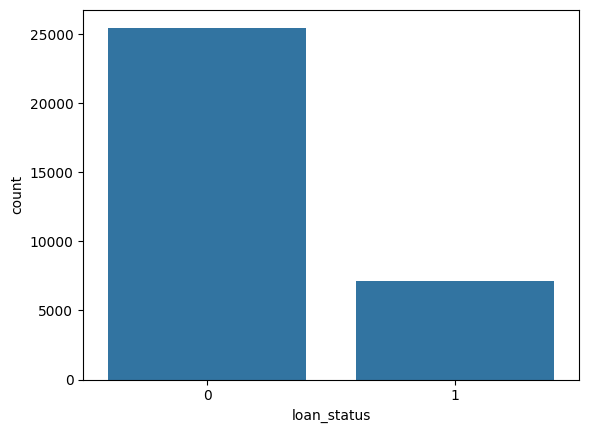

In [115]:
sns.countplot(x='loan_status',data=df)

In [116]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [117]:
numerical_cols = df.select_dtypes(include=np.number).columns
numerical_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

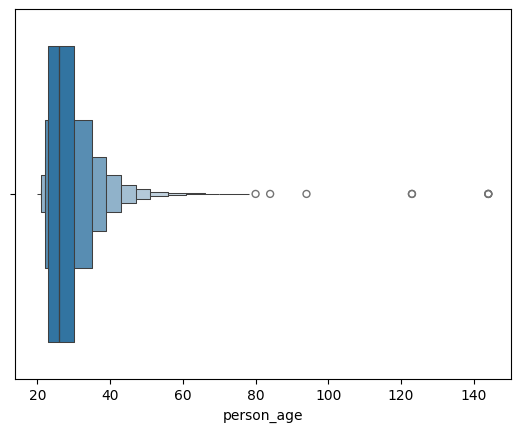

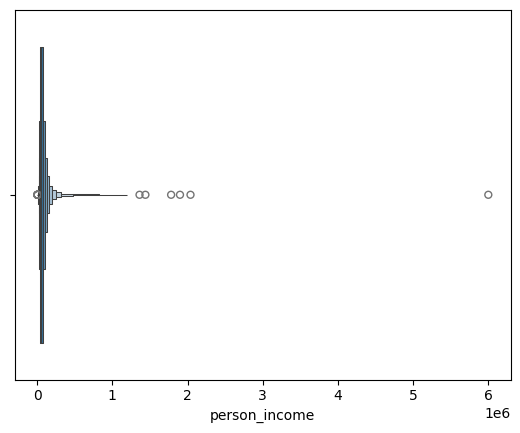

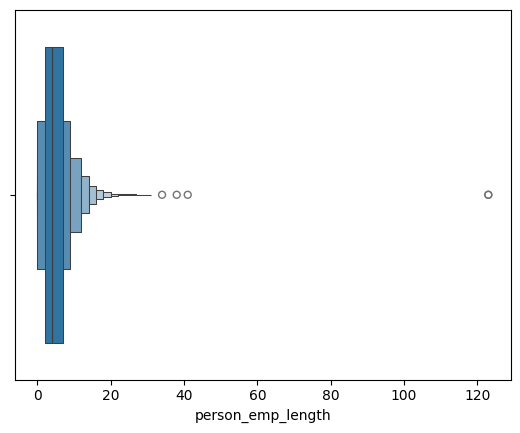

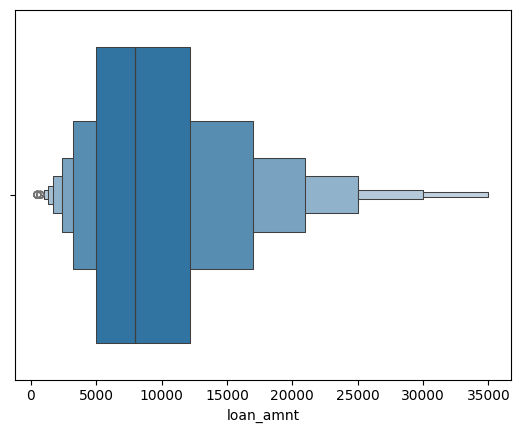

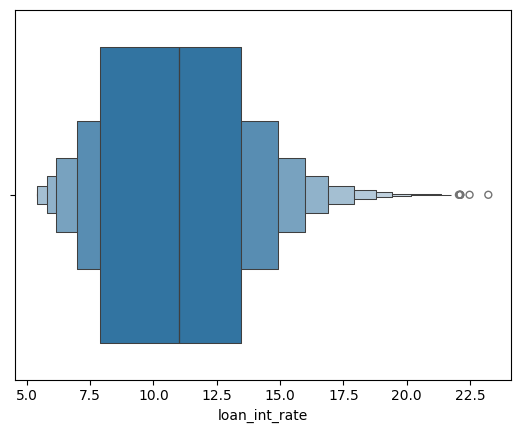

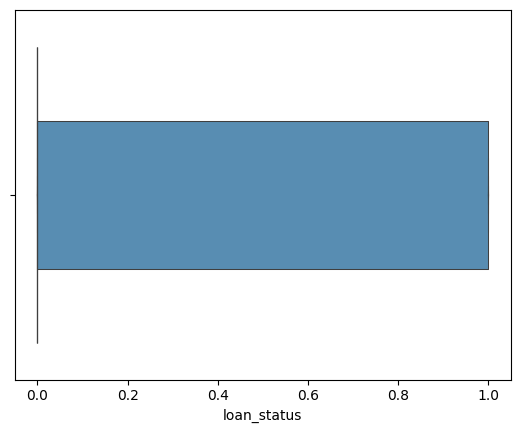

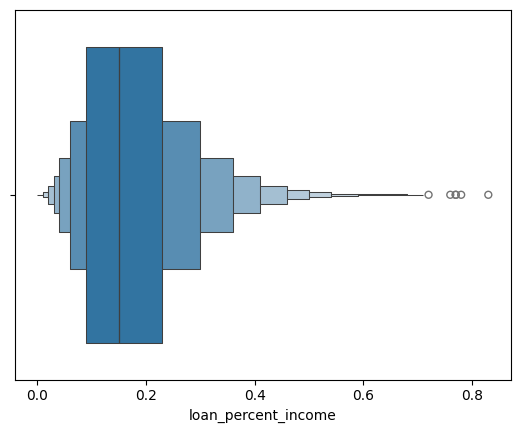

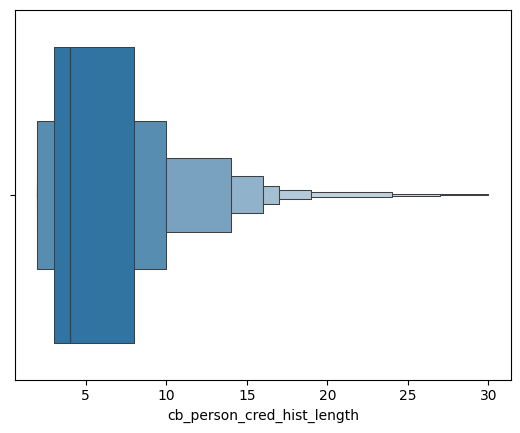

In [118]:
for col in numerical_cols:
  sns.boxenplot(x=col,data=df)
  plt.show()



In [119]:
print(max(df["person_age"]))

144


In [120]:
(df['person_age'] > 100).sum()

np.int64(5)

In [121]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

<Axes: >

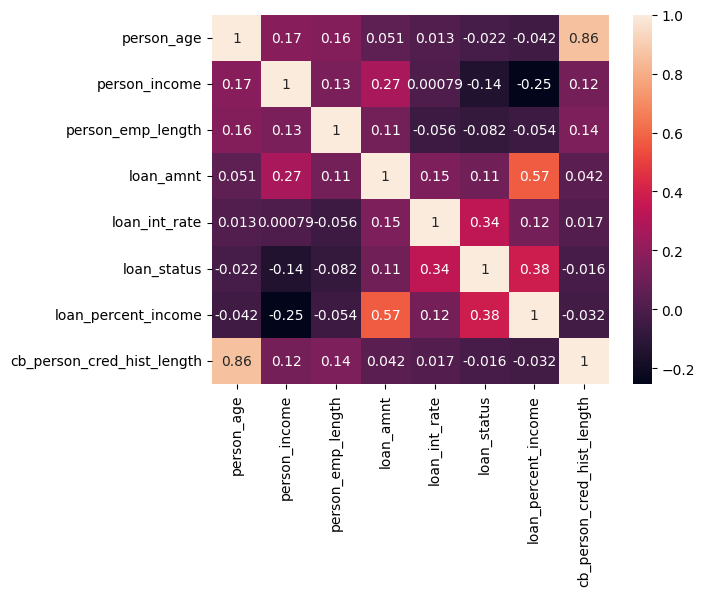

In [122]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [123]:
from numpy.random.mtrand import f
df_copy = df.copy()

print(f"Original Rows: {df_copy.shape[0]}")

# Removes Duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates: {df_copy.shape[0]}")
print(f"Totle Duplicate in df: 9165")

# Remove aages 18 or below 100
df_copy = df_copy[(df_copy['person_age'] >= 18) & (df_copy['person_age'] <= 100)]

df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

# Remove the row with zero or -ve income and loan amount
df_copy = df_copy[df_copy['loan_amnt'] > 0]

#Check if the interest rate looks realistic.
print("Loan intreset rate range from (min: 5.42% and max: 23.22%)")

Original Rows: 32581
Rows after removing duplicates: 32416
Totle Duplicate in df: 9165
Loan intreset rate range from (min: 5.42% and max: 23.22%)


In [124]:
X = df_copy.drop('loan_status',axis=1)
y = df_copy['loan_status']

In [125]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [126]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
                'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [127]:
neg, pos = np.bincount(y_train)
scale_weights = neg/pos
scale_weights

np.float64(3.6312213039485766)

**Logistic Regression Pipeline**

In [128]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Logistic Regression: impute + SCALE Numeric, impute + One-Hot-Encoding
preprocessor_lr = ColumnTransformer(
    transformers=[
        # Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),

        # Pipeline - for categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


**XGBoost Pipeline**

In [129]:
# XGBoost: impute numberic only (No Scaling), impute + One-Hot-Encoding
preprocessor_xg = ColumnTransformer(
    transformers=[
        # Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
        ]), numeric_cols),

        # Pipeline - for categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])

**Decision Tree Regressor Pipeline**

In [130]:
# Decision Tree: impute + SCALE Numeric, impute + One-Hot-Encoding
preprocessor_tree = ColumnTransformer(
    transformers=[
        # Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),

        ]), numeric_cols),

        # Pipeline - for categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ])


**Cross-Validation**

In [131]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc': 'roc_auc', 'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall', 'f1': 'f1'}
#
#

**Logistic Regression**

In [132]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

**XGBoost Model**

In [133]:
#XGBoost Model
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator = 300, random_state=42,
        max_depth=10,learning_rate=0.01,scale_pos_weight=scale_weights
        ))
])
xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.01,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=10, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

**Decision Tree Regressor Model**

In [134]:
from sklearn.tree import DecisionTreeClassifier

tree_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_tree),
    ('classifier', DecisionTreeClassifier(
        max_depth=10, random_state=42
        ))
    ])
tree_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 DecisionTreeClassifier(max_depth=10, random_state=42))])

In [135]:
from traceback import print_exc
for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline), ('XGBoost', xgb_cv_pipeline), ('Decision_Tree', tree_cv_pipeline)]:
  cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)

  print(cv_name)
  print(f"ROC AUC: {cv_results['test_roc_auc'].mean()}")
  print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
  print(f"Precision: {cv_results['test_precision'].mean()}")
  print(f"Recall: {cv_results['test_recall'].mean()}")
  print(f"F1 Score: {cv_results['test_f1'].mean()}")
  print()

Logistic Regression
ROC AUC: 0.8705112830525306
Accuracy: 0.8115949542892269
Precision: 0.5448226008889892
Recall: 0.7781450872359963
F1 Score: 0.6408013995933108



/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:01:23] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:01:24] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:01:25] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:01:26] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [09:01

XGBoost
ROC AUC: 0.9236148245962233
Accuracy: 0.9193798204591976
Precision: 0.8669770548194862
Recall: 0.7404958677685951
F1 Score: 0.7985321552075944

Decision_Tree
ROC AUC: 0.9010363752159082
Accuracy: 0.9277077954334987
Precision: 0.9508187080261112
Recall: 0.7015610651974289
F1 Score: 0.8072760701034019



In [136]:
cv_results

{'fit_time': array([0.12133527, 0.12464166, 0.11543894, 0.11458802, 0.11994696]),
 'score_time': array([0.03638029, 0.03262305, 0.03143072, 0.03477812, 0.03399062]),
 'test_roc_auc': array([0.90003796, 0.89824367, 0.90405085, 0.89942709, 0.9034223 ]),
 'test_accuracy': array([0.92624901, 0.92168914, 0.93099346, 0.9292088 , 0.93039857]),
 'test_precision': array([0.95437262, 0.94373402, 0.96603774, 0.93884892, 0.95110024]),
 'test_recall': array([0.69146006, 0.67768595, 0.70523416, 0.71900826, 0.7144169 ]),
 'test_f1': array([0.80191693, 0.78888295, 0.81528662, 0.81435257, 0.81594127])}

In [137]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced', random_state=42))
])
baseline_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', random_state=42))])

In [138]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        random_state=42,learning_rate=0.1,
        scale_pos_weight=scale_weights
        ))
])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='consta...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [139]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, precision_recall_curve, roc_curve
import seaborn as sns

def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    # 1. Fixed: Passed X_test into the predict function

    y_pred_prob = model.predict_proba(X_test)[:, 1]

    if threshold:
      y_pred = (y_pred_prob > threshold).astype(int)
    else:
      y_pred = model.predict(X_test)

    # 2. Fixed: Renamed variables to avoid shadowing the imported functions
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    # 3. Confusion Matrix DataFrame
    cm = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)
    cm_df = pd.DataFrame(cm, index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])

    # Print results nicely
    print(f"=== Evaluation for {model_name} ===")
    #print(f"Best Threshold: {best_threshold}")
    print(f"Accuracy:  {acc:.2f}")
    print(f"Precision: {prec:.2f}")
    print(f"Recall:    {rec:.2f}")
    print(f"F1 Score:  {f1:.2f}\n")

    print("Confusion DataFrame:")
    print(cm_df)
    print("="*50 + "\n")
    print("Classification Report:")
    print(class_report)
    print("="*50 + "\n")

    # Plotting Confusion Matrix
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', cbar=False)
    plt.xlabel('Predicted Value')
    plt.ylabel('Actual value')

    # Plotting ROC-AUC curve
    plt.figure(figsize=(6, 4))
    precision, recall, thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recall, precision, label='Precision-Recall Curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.legend()

    print(f"Threshold:  {thresholds}\n")
    print("="*50 + "\n")
    # Return metrics as a dictionary for easy comparison later
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1
    }


=== Evaluation for Baceline Logistic Model ===
Accuracy:  0.82
Precision: 0.56
Recall:    0.79
F1 Score:  0.65

Confusion DataFrame:
          Predicted 0  Predicted 1
Actual 0         4094          849
Actual 1          290         1072

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88      4943
           1       0.56      0.79      0.65      1362

    accuracy                           0.82      6305
   macro avg       0.75      0.81      0.77      6305
weighted avg       0.85      0.82      0.83      6305


Threshold:  [0.00155757 0.00464729 0.00565086 ... 0.99823114 0.99837602 0.99855014]




{'Model': 'Baceline Logistic Model',
 'Accuracy': 0.8193497224425059,
 'Precision': 0.5580426861009891,
 'Recall': 0.7870778267254038,
 'F1 Score': 0.6530612244897959}

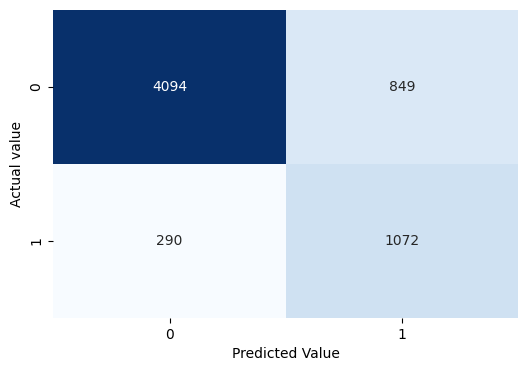

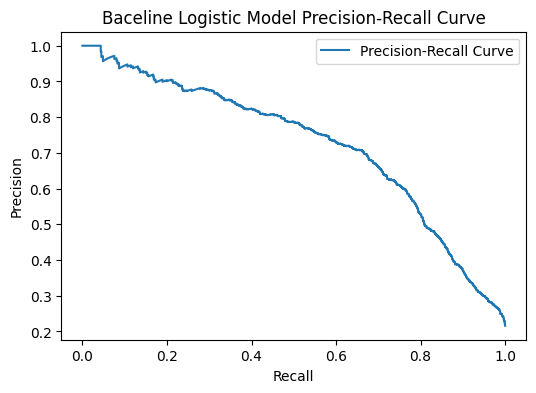

In [140]:
baseline_model.fit(X_train, y_train)
evaluate_model("Baceline Logistic Model", baseline_model, X_test, y_test)

=== Evaluation for XGBClassifier Model ===
Accuracy:  0.92
Precision: 0.82
Recall:    0.79
F1 Score:  0.81

Confusion DataFrame:
          Predicted 0  Predicted 1
Actual 0         4711          232
Actual 1          281         1081

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4943
           1       0.82      0.79      0.81      1362

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.88      6305
weighted avg       0.92      0.92      0.92      6305


Threshold:  [2.8442466e-04 2.9906811e-04 2.9967749e-04 ... 9.9938023e-01 9.9938178e-01
 9.9961311e-01]




{'Model': 'XGBClassifier Model',
 'Accuracy': 0.9186360031720856,
 'Precision': 0.8233054074638233,
 'Recall': 0.7936857562408223,
 'F1 Score': 0.8082242990654206}

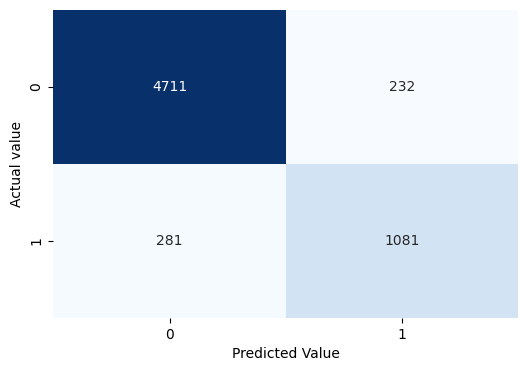

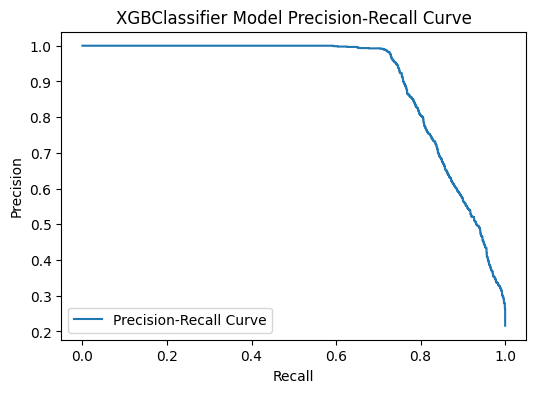

In [141]:
xg_model.fit(X_train, y_train)
evaluate_model("XGBClassifier Model", xg_model, X_test, y_test)

=== Evaluation for Decision Tree Model ===
Accuracy:  0.93
Precision: 0.97
Recall:    0.72
F1 Score:  0.83

Confusion DataFrame:
          Predicted 0  Predicted 1
Actual 0         4908           35
Actual 1          381          981

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.99      0.96      4943
           1       0.97      0.72      0.83      1362

    accuracy                           0.93      6305
   macro avg       0.95      0.86      0.89      6305
weighted avg       0.94      0.93      0.93      6305


Threshold:  [0.         0.01960784 0.02139037 0.03992273 0.04545455 0.05790109
 0.06896552 0.07758621 0.07986111 0.0816777  0.08333333 0.08428246
 0.08888889 0.09433962 0.10067114 0.11291194 0.11764706 0.12643678
 0.13333333 0.13636364 0.14035088 0.14285714 0.15229111 0.15346535
 0.17073171 0.17391304 0.18113208 0.18181818 0.19354839 0.23611111
 0.24390244 0.24590164 0.25       0.26666667 0.30588235 0.33333333


{'Model': 'Decision Tree Model',
 'Accuracy': 0.934020618556701,
 'Precision': 0.9655511811023622,
 'Recall': 0.7202643171806168,
 'F1 Score': 0.8250630782169891}

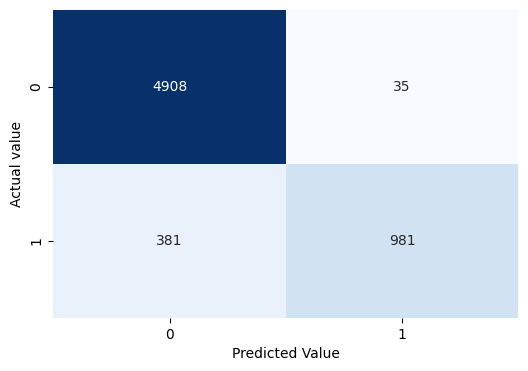

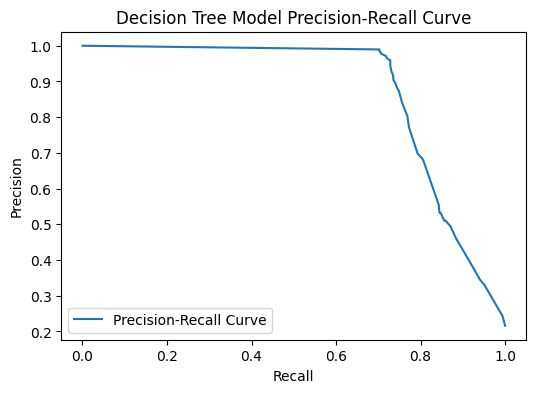

In [142]:
tree_cv_pipeline.fit(X_train, y_train)
evaluate_model("Decision Tree Model", tree_cv_pipeline, X_test, y_test)

**hyperparameter tuning**

In [143]:
import numpy as np
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth": randint(3, 9),
    "classifier__learning_rate": uniform(0.01, 0.49),  # loc=0.01, scale=0.49 -> range [0.01, 0.5]
    "classifier__subsample": uniform(0.4, 0.2),  # Rows sampling [0.4, 0.6]
    "classifier__colsample_bytree": uniform(0.4, 0.2),  # Column sampling [0.4, 0.6]
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0, 5),  # Range [0, 5]
}


In [144]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=200,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median'))]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income',
                                                                                'cb_person_cred_hist_length...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ef4c1b33770>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7ef4c1de1480>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7ef4c1d42570>},
                   scoring='average_precision', verbose=1)

In [145]:
print(f"paremeter after performing Tunning {random_search.best_params_}")

paremeter after performing Tunning {'classifier__colsample_bytree': np.float64(0.5770752727736455), 'classifier__gamma': np.float64(0.372106080198949), 'classifier__learning_rate': np.float64(0.051909213719545676), 'classifier__max_depth': 6, 'classifier__min_child_weight': 2, 'classifier__n_estimators': 461, 'classifier__subsample': np.float64(0.5134854531431106)}


In [146]:
print(f"Score after performing Tunning {random_search.best_score_}")

Score after performing Tunning 0.9001499116313699


Passing the XGBoost model after performing Hyperparameter Tuning

=== Evaluation for XGBoost ===
Accuracy:  0.92
Precision: 0.83
Recall:    0.80
F1 Score:  0.82

Confusion DataFrame:
          Predicted 0  Predicted 1
Actual 0         4719          224
Actual 1          266         1096

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95      4943
           1       0.83      0.80      0.82      1362

    accuracy                           0.92      6305
   macro avg       0.89      0.88      0.88      6305
weighted avg       0.92      0.92      0.92      6305


Threshold:  [8.31389116e-05 9.85418374e-05 1.00240206e-04 ... 9.99943852e-01
 9.99965191e-01 9.99989510e-01]




{'Model': 'XGBoost',
 'Accuracy': 0.922283901665345,
 'Precision': 0.8303030303030303,
 'Recall': 0.8046989720998532,
 'F1 Score': 0.8173005219985086}

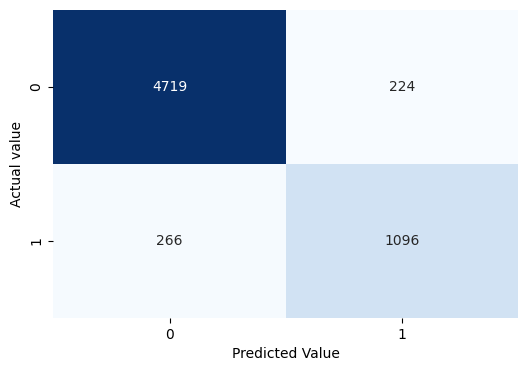

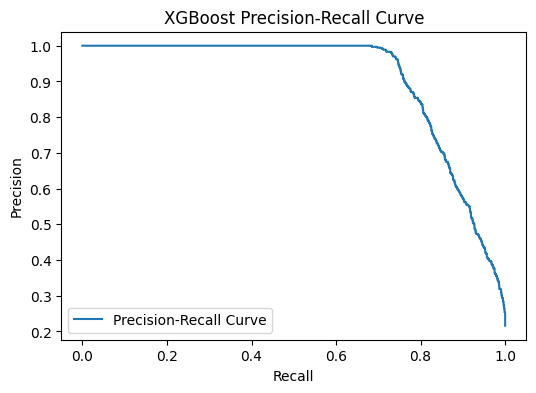

In [147]:
evaluate_model("XGBoost", random_search, X_test, y_test)

=== Evaluation for XGBoost ===
Accuracy:  0.94
Precision: 0.98
Recall:    0.73
F1 Score:  0.83

Confusion DataFrame:
          Predicted 0  Predicted 1
Actual 0         4925           18
Actual 1          373          989

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96      4943
           1       0.98      0.73      0.83      1362

    accuracy                           0.94      6305
   macro avg       0.96      0.86      0.90      6305
weighted avg       0.94      0.94      0.93      6305


Threshold:  [2.8442466e-04 2.9906811e-04 2.9967749e-04 ... 9.9938023e-01 9.9938178e-01
 9.9961311e-01]




{'Model': 'XGBoost',
 'Accuracy': 0.9379857256145916,
 'Precision': 0.9821251241310824,
 'Recall': 0.7261380323054332,
 'F1 Score': 0.8349514563106796}

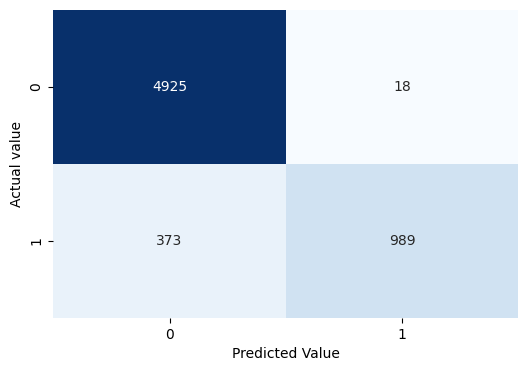

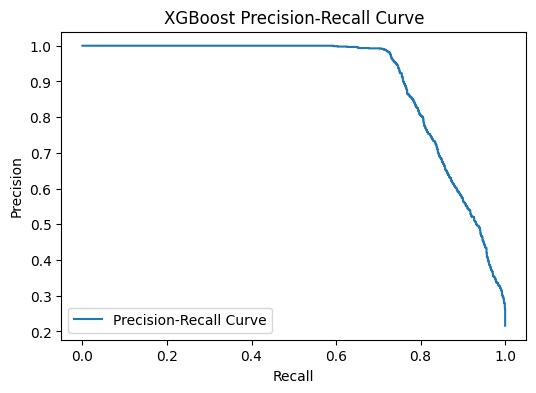

In [148]:
prob = xg_model.predict_proba(X_test)[:, 1]
# For each threshold calculate Precision and Recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)

# Calculate F1 score for each threshold (Changed '-' to '*')
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]

# Evaluate the XGBoost model using that threshold.
evaluate_model("XGBoost", xg_model, X_test, y_test, best_threshold)


Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilities using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibration)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature parameter

**Probality Calibration**

**#1. Calibrated XGboost model**

In [149]:
#1. Calibrated XGboost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    cv=5,
    method='sigmoid'
)

calibrated_model.fit(X_train, y_train)


CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median'))]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.051909213719545676),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=6,
                                                                max_leaves=None,
                                                                min_child_weight=2,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=461,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

**#2. Git Probabilites**

In [150]:
#2. Git Probabilites
uncalibrated_prob = xg_model.predict_proba(X_test)[:, 1]
uncalibrated_prob


array([0.8254656 , 0.25111562, 0.9782833 , ..., 0.48520026, 0.07587515,
       0.05467961], dtype=float32)

In [151]:
calibrated_prob = calibrated_model.predict_proba(X_test)[:, 1]
calibrated_prob

array([0.57573237, 0.02749861, 0.95161283, ..., 0.39393506, 0.02419266,
       0.01456977])

**#3. create Calibration curves**

In [152]:
#3. create Calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated_prob, n_bins=10)
actual_cal, predicted_cal = calibration_curve(y_test, calibrated_prob, n_bins=10)

**#4. Plot Uncalibrated**

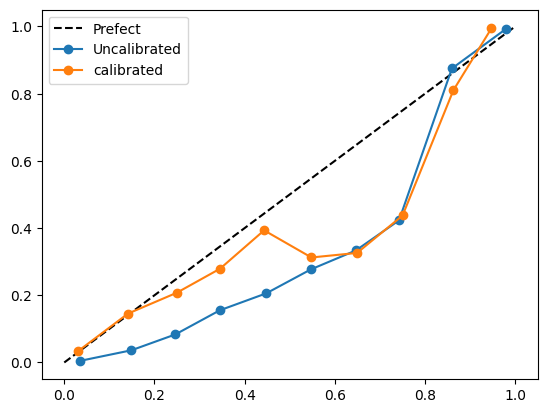

In [153]:
#4. plot
plt.plot([0,1], [0,1], 'k--', label='Prefect')
plt.plot(
    predicted_uncal,
    actual_uncal,
    marker='o',
    linestyle='-',
    label='Uncalibrated'
)
plt.plot(
    predicted_cal,
    actual_cal,
    marker='o',
    linestyle='-',
    label='calibrated'
)
plt.legend()
plt.show()

**SHAP**

**SHAP can tell you how each fetaure contributed**

SHAP tells which features pushed the predictions up or down and how much?

**#1. Install SHAP if not exists**

In [154]:
!pip install shap
import shap

In [155]:
#2. Git the Trained XGBoost classifier model out of the pipeline.

xgb_classifier = xg_model.named_steps['classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [156]:
#3. transform X_test using the same preprocessing used for training.
X_test_transformes = xg_model.named_steps['preprocessor'].transform(X_test)
X_test_transformes

array([[2.4000e+01, 3.0000e+04, 1.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [2.3000e+01, 6.0000e+04, 6.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [2.9000e+01, 1.8000e+04, 2.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       ...,
       [2.5000e+01, 4.8996e+04, 8.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [2.7000e+01, 1.1500e+05, 1.1000e+01, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00],
       [3.2000e+01, 5.0000e+04, 0.0000e+00, ..., 0.0000e+00, 1.0000e+00,
        0.0000e+00]])

In [157]:
#4.
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()
feature_names

array(['num__person_age', 'num__person_income', 'num__person_emp_length',
       'num__loan_amnt', 'num__loan_int_rate', 'num__loan_percent_income',
       'num__cb_person_cred_hist_length',
       'cat__person_home_ownership_MORTGAGE',
       'cat__person_home_ownership_OTHER',
       'cat__person_home_ownership_OWN',
       'cat__person_home_ownership_RENT',
       'cat__loan_intent_DEBTCONSOLIDATION', 'cat__loan_intent_EDUCATION',
       'cat__loan_intent_HOMEIMPROVEMENT', 'cat__loan_intent_MEDICAL',
       'cat__loan_intent_PERSONAL', 'cat__loan_intent_VENTURE',
       'cat__loan_grade_A', 'cat__loan_grade_B', 'cat__loan_grade_C',
       'cat__loan_grade_D', 'cat__loan_grade_E', 'cat__loan_grade_F',
       'cat__loan_grade_G', 'cat__cb_person_default_on_file_N',
       'cat__cb_person_default_on_file_Y'], dtype=object)

In [158]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformes, columns=feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,...,cat__loan_intent_VENTURE,cat__loan_grade_A,cat__loan_grade_B,cat__loan_grade_C,cat__loan_grade_D,cat__loan_grade_E,cat__loan_grade_F,cat__loan_grade_G,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [159]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)
explainer

In [160]:
#7. Calculate SHAP values for every raw in the test set
shap_value = explainer.shap_values(X_test_df)
shap_value

array([[-1.7525564e-01, -1.0555401e-01,  1.2984274e-01, ...,
        -7.3516299e-03, -3.8879909e-02,  0.0000000e+00],
       [ 4.7165085e-02, -8.7262326e-01, -9.4737314e-02, ...,
        -9.2151780e-03, -7.5508673e-03,  0.0000000e+00],
       [ 7.8027323e-02,  3.5025654e+00,  1.2711690e-01, ...,
        -7.3584518e-03,  7.7456667e-04,  0.0000000e+00],
       ...,
       [-8.6244913e-03,  5.8208084e-01,  7.2391242e-02, ...,
        -9.2837382e-03, -1.1459960e-02,  0.0000000e+00],
       [ 2.0838849e-02, -1.0313793e+00,  4.3692421e-02, ...,
        -9.2305308e-03, -1.1398584e-02,  0.0000000e+00],
       [-1.3665082e-01, -5.0866711e-01,  2.6854105e-02, ...,
        -8.8342456e-03, -1.0388625e-02,  0.0000000e+00]], dtype=float32)

**Globle explainer**

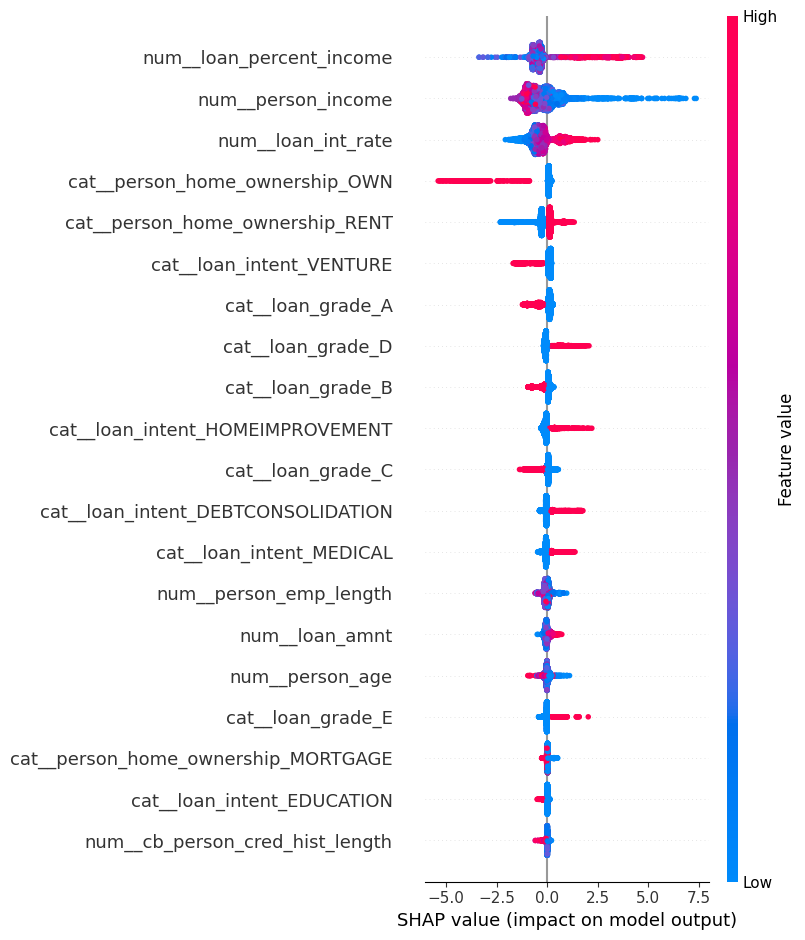

In [161]:
shap.summary_plot(shap_value, X_test_df)

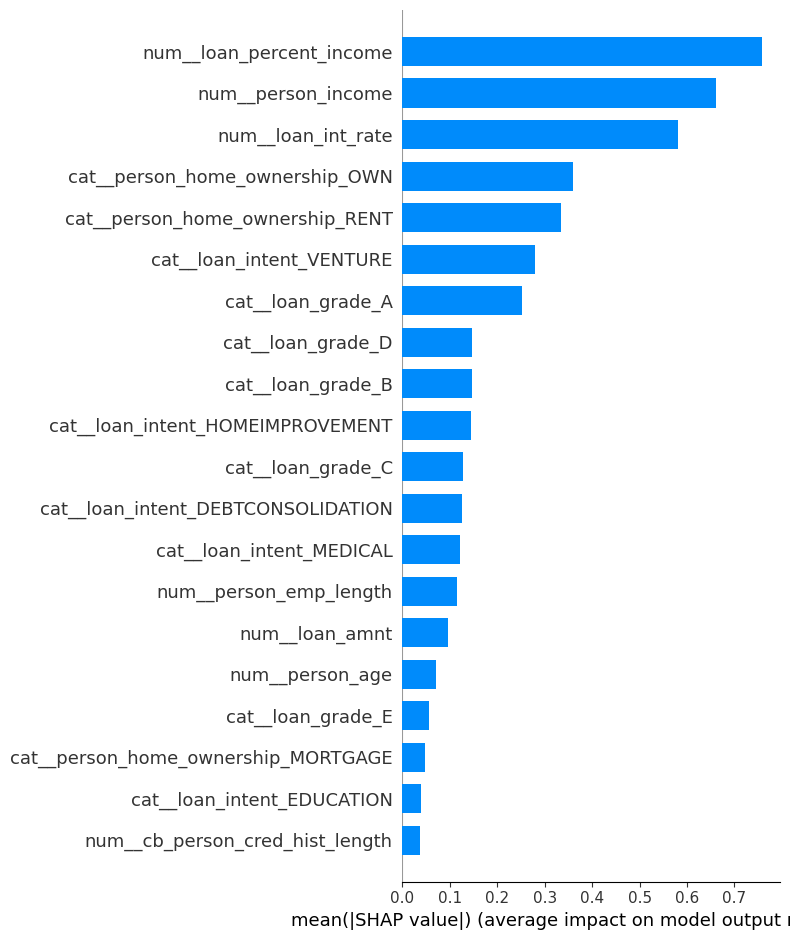

In [162]:
shap.summary_plot(shap_value, X_test_df, plot_type='bar')


**Local explainer**

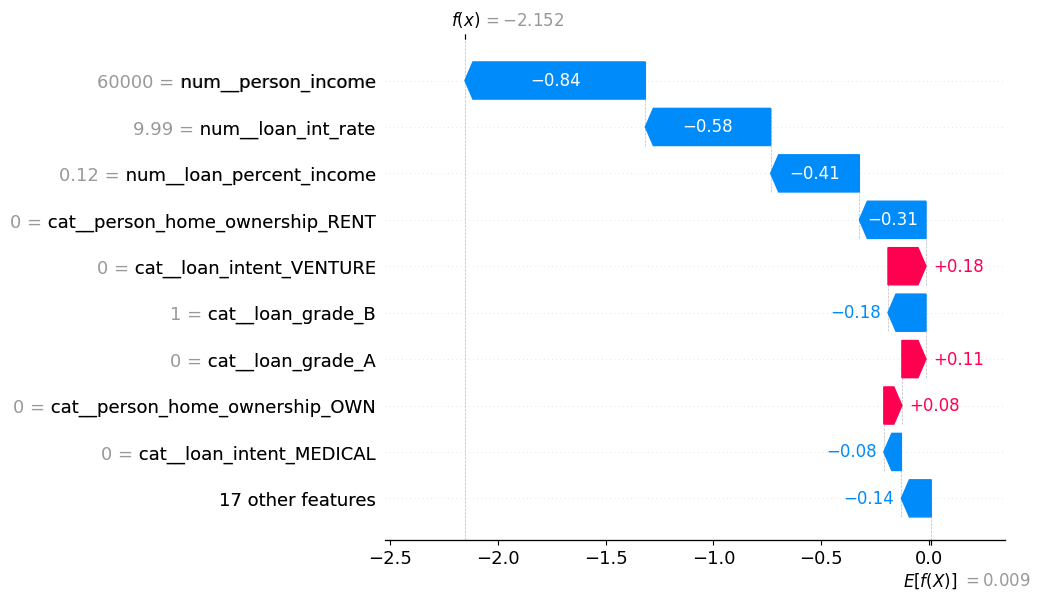

In [163]:
# 1. जिस रो (आवेदक) को एक्सप्लेन करना है उसका इंडेक्स चुनें (जैसे कि 5वां आवेदक)
row_index = 5

# 2. SHAP Explanation ऑब्जेक्ट को मैन्युअल रूप से तैयार करें
# यह तब काम आता है जब shap_values एक सामान्य NumPy array के रूप में हों
shap.plots.waterfall(
    shap.Explanation(
      values = shap_value[row_index],              # उस रो के SHAP values (कंट्रीब्यूशन)
      base_values = explainer.expected_value,       # मॉडल का बेसलाइन (एवरेज) प्रेडिक्शन
      data = X_test_df.iloc[row_index],             # उस आवेदक की वास्तविक इनपुट वैल्यूज
      feature_names = feature_names                 # वन-हॉट एनकोडिंग के बाद के नए फीचर्स के नाम
  )
)


In [164]:
y_pred = random_search.predict(X_test)

In [165]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,1
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


**Analyzing False positives & False Negatives**

In [166]:
# Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]

# Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]


**Our model False Negative are risky people wrongly makedsafe**

In [167]:
print(f"False Positive: {len(false_positive)}")
print(f"False Negative: {len(false_negative)}")
print(len(false_positive) -  len(false_negative))

False Positive: 224
False Negative: 266
-42


In [172]:
from sklearn.metrics import precision_recall_curve
import numpy as np

# 1. Get probabilities from the CALIBRATED model, not the old xg_model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

# 2. Re-run the same threshold search, now on the correct probability scale
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold:", best_threshold)


New threshold: 0.7583911390747435


**Save Model**

In [168]:
import joblib
joblib.dump(calibrated_model,'credit_risk_model.pkl')

['credit_risk_model.pkl']

In [173]:
joblib.dump(best_threshold,'best_threshold.pkl')

['best_threshold.pkl']